<a href="https://colab.research.google.com/github/chelsajn/novapay-funnel_analysis/blob/main/novapay_funnel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np, pandas as pd, sqlite3
rng = np.random.default_rng(42)
n = 10000

users = pd.DataFrame({
    "user_id": range(1, n + 1),
    "signup_time": pd.to_datetime("2026-01-01") + pd.to_timedelta(rng.integers(0, 180*24*60, n), unit="m"),
    "channel": rng.choice(["Organic", "Paid Social", "Referral", "Google Ads"], n, p=[0.30, 0.30, 0.15, 0.25]),
    "device": rng.choice(["Android", "iOS"], n, p=[0.68, 0.32]),
    "city": rng.choice(["Bangalore", "Mumbai", "Delhi", "Hyderabad", "Chennai", "Kochi"], n, p=[0.22, 0.22, 0.20, 0.14, 0.12, 0.10]),
    "age_band": rng.choice(["18-24", "25-34", "35-44", "45+"], n, p=[0.30, 0.40, 0.20, 0.10]),
})

# conversion probabilities (the hidden story)
p_kyc = np.where(users.device == "iOS", 0.82, 0.70)
p_kyc = np.where((users.device == "Android") & (users.channel == "Paid Social"), 0.42, p_kyc)
p_fund = np.where(users.channel == "Referral", 0.85, 0.72)
p_txn = np.where(users.age_band == "45+", 0.70, 0.86)
p_rep = np.where(users.channel == "Referral", 0.68, 0.50)

kyc = rng.random(n) < p_kyc
fund = kyc & (rng.random(n) < p_fund)
txn = fund & (rng.random(n) < p_txn)
rep = txn & (rng.random(n) < p_rep)

def delay(mean_hours):
    return pd.to_timedelta(rng.exponential(mean_hours, n), unit="h")

t_kyc = users.signup_time + delay(6)
t_fund = t_kyc + delay(20)
t_txn = t_fund + delay(10)
t_rep = t_txn + delay(24 * 9)

def stage(name, mask, times):
    return pd.DataFrame({"user_id": users.user_id[mask], "event": name, "event_time": times[mask]})

events = pd.concat([
    stage("signup", np.ones(n, dtype=bool), users.signup_time),
    stage("kyc_verified", kyc, t_kyc),
    stage("wallet_funded", fund, t_fund),
    stage("first_txn", txn, t_txn),
    stage("repeat_txn", rep, t_rep),
]).sort_values(["user_id", "event_time"]).reset_index(drop=True)

# save as CSV (for Power BI) and SQLite (for SQL practice)
users.to_csv("users.csv", index=False)
events.to_csv("events.csv", index=False)
con = sqlite3.connect("novapay.db")
users.to_sql("users", con, if_exists="replace", index=False)
events.to_sql("events", con, if_exists="replace", index=False)

print(events.event.value_counts())

event
signup           10000
kyc_verified      6861
wallet_funded     5050
first_txn         4241
repeat_txn        2249
Name: count, dtype: int64


In [4]:
import sqlite3, pandas as pd
con = sqlite3.connect("novapay.db")
def q(sql): return pd.read_sql(sql, con)

con.execute("DROP VIEW IF EXISTS funnel")
con.execute("""
CREATE VIEW funnel AS
SELECT u.user_id, u.channel, u.device, u.city, u.age_band,
  MIN(CASE WHEN e.event = 'signup' THEN e.event_time END) AS signup_at,
  MIN(CASE WHEN e.event = 'kyc_verified' THEN e.event_time END) AS kyc_at,
  MIN(CASE WHEN e.event = 'wallet_funded' THEN e.event_time END) AS funded_at,
  MIN(CASE WHEN e.event = 'first_txn' THEN e.event_time END) AS txn_at,
  MIN(CASE WHEN e.event = 'repeat_txn' THEN e.event_time END) AS rep_at
FROM users u
LEFT JOIN events e ON u.user_id = e.user_id
GROUP BY u.user_id
""")

In [3]:
q("""
SELECT COUNT(signup_at) AS signups, COUNT(kyc_at) AS kyc, COUNT(funded_at) AS funded,
  COUNT(txn_at) AS first_txn, COUNT(rep_at) AS repeat_txn,
  ROUND(100.0 * COUNT(kyc_at) / COUNT(signup_at), 1) AS signup_to_kyc,
  ROUND(100.0 * COUNT(funded_at) / COUNT(kyc_at), 1) AS kyc_to_fund,
  ROUND(100.0 * COUNT(txn_at) / COUNT(funded_at), 1) AS fund_to_txn,
  ROUND(100.0 * COUNT(rep_at) / COUNT(txn_at), 1) AS txn_to_repeat
FROM funnel
""")

,signups,kyc,funded,first_txn,repeat_txn,signup_to_kyc,kyc_to_fund,fund_to_txn,txn_to_repeat
0,10000,6861,5050,4241,2249,68.6,73.6,84.0,53.0


In [5]:
q("""
SELECT device, channel, COUNT(*) AS users,
  ROUND(100.0 * COUNT(kyc_at) / COUNT(*), 1) AS kyc_rate
FROM funnel
GROUP BY device, channel
ORDER BY kyc_rate
""")

,device,channel,users,kyc_rate
0,Android,Paid Social,2025,42.7
1,Android,Organic,1991,70.1
2,Android,Google Ads,1645,70.3
3,Android,Referral,1061,71.5
4,iOS,Referral,538,79.7
5,iOS,Organic,994,81.8
6,iOS,Paid Social,948,81.9
7,iOS,Google Ads,798,83.8


In [6]:
q("""
SELECT age_band, COUNT(funded_at) AS funded,
  ROUND(100.0 * COUNT(txn_at) / COUNT(funded_at), 1) AS fund_to_txn
FROM funnel
GROUP BY age_band
ORDER BY fund_to_txn
""")

,age_band,funded,fund_to_txn
0,45+,513,69.4
1,18-24,1479,84.9
2,35-44,1062,85.2
3,25-34,1996,86.4


In [7]:
q("""
SELECT channel, COUNT(*) AS users,
  ROUND(100.0 * COUNT(funded_at) / COUNT(kyc_at), 1) AS kyc_to_fund,
  ROUND(100.0 * COUNT(rep_at) / COUNT(txn_at), 1) AS txn_to_repeat
FROM funnel
GROUP BY channel
ORDER BY txn_to_repeat DESC
""")

,channel,users,kyc_to_fund,txn_to_repeat
0,Referral,1599,83.4,65.5
1,Paid Social,2973,72.5,51.6
2,Organic,2985,70.4,50.1
3,Google Ads,2443,72.1,48.3


In [8]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

users = pd.read_csv("users.csv", parse_dates=["signup_time"])
events = pd.read_csv("events.csv", parse_dates=["event_time"])
# If Colab says file not found, swap in your GitHub link:
# users = pd.read_csv("https://raw.githubusercontent.com/chelsajn/novapay-funnel_analysis/main/users.csv", parse_dates=["signup_time"])

wide = events.pivot_table(index="user_id", columns="event", values="event_time", aggfunc="min")
df = users.merge(wide, on="user_id", how="left")
for s in ["kyc_verified", "wallet_funded", "first_txn", "repeat_txn"]:
    df["got_" + s] = df[s].notna()

# data validation checks
print("Duplicate users:", users.user_id.duplicated().sum())
print("Nulls in users table:", users.isna().sum().sum())
print("Duplicate events:", events.duplicated(["user_id", "event"]).sum())
print("KYC before signup:", (df.kyc_verified < df.signup).sum())
print("Funded without KYC:", (df.got_wallet_funded & ~df.got_kyc_verified).sum())
print("Txn without funding:", (df.got_first_txn & ~df.got_wallet_funded).sum())
print("Repeat without first txn:", (df.got_repeat_txn & ~df.got_first_txn).sum())

Duplicate users: 0
Nulls in users table: 0
Duplicate events: 0
KYC before signup: 0
Funded without KYC: 0
Txn without funding: 0
Repeat without first txn: 0


In [9]:
def test(data, group_col, outcome_col, label):
    ct = pd.crosstab(data[group_col], data[outcome_col])
    chi2, p, _, _ = chi2_contingency(ct)
    print(f"{label}: p = {p:.2e}")

android = df[df.device == "Android"].copy()
android["segment"] = np.where(android.channel == "Paid Social", "Paid Social", "Other")
test(android, "segment", "got_kyc_verified", "Android Paid Social vs other Android (KYC)")

funded = df[df.got_wallet_funded].copy()
funded["segment"] = np.where(funded.age_band == "45+", "45+", "Under 45")
test(funded, "segment", "got_first_txn", "45+ vs under 45 (first txn)")

txn_users = df[df.got_first_txn].copy()
txn_users["segment"] = np.where(txn_users.channel == "Referral", "Referral", "Other")
test(txn_users, "segment", "got_repeat_txn", "Referral vs other channels (repeat)")

Android Paid Social vs other Android (KYC): p = 8.11e-103
45+ vs under 45 (first txn): p = 3.80e-21
Referral vs other channels (repeat): p = 8.66e-16


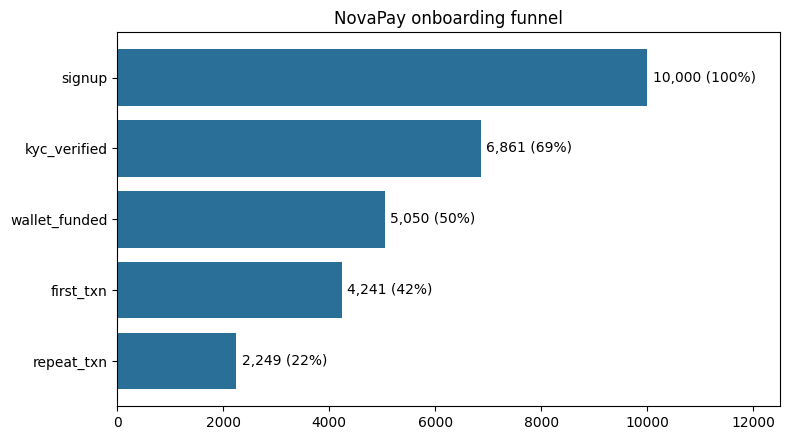

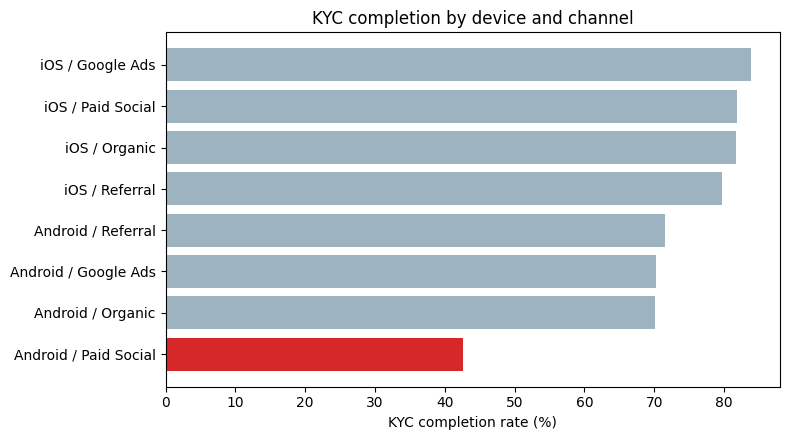

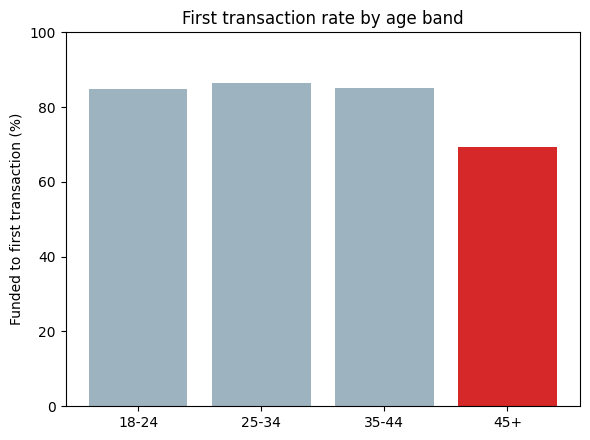

In [11]:
# Chart 1: funnel
stages = ["signup", "kyc_verified", "wallet_funded", "first_txn", "repeat_txn"]
counts = [df[s].notna().sum() for s in stages]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(stages, counts, color="#2a6f97")
ax.invert_yaxis()
for i, c in enumerate(counts):
    ax.text(c + 100, i, f"{c:,} ({100*c/counts[0]:.0f}%)", va="center")
ax.set_xlim(0, 12500)
ax.set_title("NovaPay onboarding funnel")
plt.tight_layout(); plt.savefig("funnel.png", dpi=200); plt.show()

# Chart 2: KYC rate by device and channel
g = df.groupby(["device", "channel"]).got_kyc_verified.mean().mul(100).sort_values()
colors = ["#d62828" if i == ("Android", "Paid Social") else "#9db4c0" for i in g.index]
labels = [f"{d} / {c}" for d, c in g.index]
plt.figure(figsize=(8, 4.5))
plt.barh(labels, g.values, color=colors)
plt.xlabel("KYC completion rate (%)")
plt.title("KYC completion by device and channel")
plt.tight_layout(); plt.savefig("kyc_by_segment.png", dpi=200); plt.show()

# Chart 3: first transaction by age band
a = funded.groupby("age_band").got_first_txn.mean().mul(100)
colors = ["#d62828" if x == "45+" else "#9db4c0" for x in a.index]
plt.figure(figsize=(6, 4.5))
plt.bar(a.index, a.values, color=colors)
plt.ylim(0, 100)
plt.ylabel("Funded to first transaction (%)")
plt.title("First transaction rate by age band")
plt.tight_layout(); plt.savefig("txn_by_age.png", dpi=200); plt.show()

In [12]:
seg = df[(df.device == "Android") & (df.channel == "Paid Social")]
others = df[(df.device == "Android") & (df.channel != "Paid Social")]
extra_kyc = len(seg) * (others.got_kyc_verified.mean() - seg.got_kyc_verified.mean())
kyc_to_txn = df[df.got_kyc_verified].got_first_txn.mean()
extra_txn_1 = extra_kyc * kyc_to_txn

old = funded[funded.age_band == "45+"]
rest = funded[funded.age_band != "45+"]
extra_txn_2 = len(old) * (rest.got_first_txn.mean() - old.got_first_txn.mean())

total = df.got_first_txn.sum()
print(f"Fix 1 (Android Paid Social KYC): +{extra_kyc:.0f} verified, +{extra_txn_1:.0f} first txns ({100*extra_txn_1/total:.1f}% uplift)")
print(f"Fix 2 (45+ activation): +{extra_txn_2:.0f} first txns ({100*extra_txn_2/total:.1f}% uplift)")

Fix 1 (Android Paid Social KYC): +563 verified, +348 first txns (8.2% uplift)
Fix 2 (45+ activation): +83 first txns (2.0% uplift)
